# 04 — OULAD leakage-safe early-warning evaluation

This notebook evaluates an early-warning version of the enrollment-risk task. The target remains the final course outcome (`Fail`/`Withdrawn` versus `Pass`/`Distinction`), but each feature matrix is built as if the planner stopped observing the course at a specified course-relative day. The statistical unit remains the enrollment, so every metric is calculated over enrollment-level predictions.

The evaluation uses three explicit safeguards:

1. assessment submissions and VLE activity after the cutoff are excluded;
2. future `date_unregistration` is excluded from cutoff features; and
3. the latest course presentation is held out as test data, so later presentations are not used to train earlier predictions.

This is an evaluation of early-warning feasibility, not a claim that a deployed planner would know the final outcome at prediction time. The measured values are retrospective discrimination statistics under an information-availability constraint, not prospective intervention effects. The purpose is to determine whether the planner could identify learners for review while there is still time to offer support.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.loader import load_oulad_tables
from src.data.cleaner import clean_oulad_tables
from src.features.feature_engineering import build_oulad_features
from src.models.baseline import (
    MODEL_NAMES,
    split_time_aware_data,
    train_time_aware_baselines,
)

DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'oulad'
CUTOFFS = [30, 60, 90]
tables = clean_oulad_tables(load_oulad_tables(DATA_DIR))
print(f'Loaded cleaned OULAD tables from {DATA_DIR}')

Loaded cleaned OULAD tables from D:\AI PROJECTS\C++\Smart-Study-Planner\data\processed\oulad


## Observation availability

The counts below show how much dated information exists by cutoff. Missing dates are not treated as observed evidence. The purpose of this audit is to make the information set explicit before interpreting model performance: a feature may be used at a cutoff only when its source record has a valid course-relative date at or before that cutoff. The 30-, 60-, and 90-day checkpoints represent early, mid-course, and later actionable observation windows. Comparing them quantifies the trade-off between giving the planner more evidence and preserving lead time for intervention; the checkpoints are evaluation choices, not claims of universal optimality.

In [2]:
availability = []
for cutoff in CUTOFFS:
    availability.append({
        'cutoff_days': cutoff,
        'assessment_submissions_observed': int((tables['studentAssessment']['date_submitted'].notna() & (tables['studentAssessment']['date_submitted'] <= cutoff)).sum()),
        'vle_rows_observed': int((tables['studentVle']['date'].notna() & (tables['studentVle']['date'] <= cutoff)).sum()),
        'registrations_with_future_unregistration_excluded': int(tables['studentRegistration']['date_unregistration'].notna().sum()),
    })
availability_df = pd.DataFrame(availability)
display(availability_df.style.background_gradient(cmap='YlGnBu'))

,cutoff_days,assessment_submissions_observed,vle_rows_observed,registrations_with_future_unregistration_excluded
0,30,26522,2980575,10072
1,60,54744,4499256,10072
2,90,71051,5486878,10072


## Four-model time-aware evaluation

At each cutoff, the feature builder is rerun from the cleaned tables. The four baselines are logistic regression, random forest, extra-trees, and histogram gradient boosting. The model ranking is based on validation PR-AUC, then validation ROC-AUC, validation balanced accuracy, and validation F1. The latest presentation is locked for testing, the preceding presentation is used for validation, and repeated learners are kept out of later partitions. Rebuilding the feature matrix at each cutoff prevents later observations from being silently carried into an earlier prediction scenario.

In [3]:
evaluation_rows = []
fitted_by_cutoff = {}
split_by_cutoff = {}
for cutoff in CUTOFFS:
    features = build_oulad_features(tables, clean=False, cutoff_days=cutoff)
    assert 'date_unregistration' not in features.columns
    best_name, fitted, model_results = train_time_aware_baselines(features)
    train_features, test_features, train_target, test_target = split_time_aware_data(features)
    fitted_by_cutoff[cutoff] = fitted
    split_by_cutoff[cutoff] = (test_features, test_target)
    for model_name in MODEL_NAMES:
        row = {'cutoff_days': cutoff, 'model': model_name, 'selected': model_name == best_name}
        row.update(model_results[model_name])
        evaluation_rows.append(row)

results = pd.DataFrame(evaluation_rows)
display(results.sort_values(['cutoff_days', 'validation_pr_auc'], ascending=[True, False]).style.background_gradient(cmap='viridis', subset=['validation_pr_auc', 'pr_auc', 'balanced_accuracy', 'f1']))

D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,cutoff_days,model,selected,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score,confusion_matrix,threshold_diagnostics,subgroup_metrics,validation_pr_auc,validation_roc_auc,validation_balanced_accuracy,validation_f1,validation_selected_threshold,test_at_validation_threshold,n_samples,n_train,n_validation,n_test,random_state,selection_split
3,30,hist_gradient_boosting,True,0.730551,0.730635,0.743793,0.727899,0.735760,0.802754,0.825576,0.186244,"[[4002, 1455], [1579, 4224]]","[{'threshold': 0.01, 'predicted_positive_count': 11260, 'predicted_positive_rate': 1.0, 'precision': 0.5153641207815275, 'recall': 1.0, 'f1': 0.6801851960382114}, {'threshold': 0.02, 'predicted_positive_count': 11260, 'predicted_positive_rate': 1.0, 'precision': 0.5153641207815275, 'recall': 1.0, 'f1': 0.6801851960382114}, {'threshold': 0.05, 'predicted_positive_count': 11257, 'predicted_positive_rate': 0.9997335701598579, 'precision': 0.5155014657546415, 'recall': 1.0, 'f1': 0.6803048065650644}, {'threshold': 0.1, 'predicted_positive_count': 10974, 'predicted_positive_rate': 0.9746003552397868, 'precision': 0.5263349735739019, 'recall': 0.9953472341892124, 'f1': 0.6885617214043035}, {'threshold': 0.2, 'predicted_positive_count': 9440, 'predicted_positive_rate': 0.8383658969804618, 'precision': 0.5834745762711865, 'recall': 0.9491642254006548, 'f1': 0.7226923833890966}, {'threshold': 0.3, 'predicted_positive_count': 8101, 'predicted_positive_rate': 0.719449378330373, 'precision': 0.6336254783360079, 'recall': 0.8845424780286059, 'f1': 0.7383486766398158}, {'threshold': 0.4, 'predicted_positive_count': 6720, 'predicted_positive_rate': 0.5968028419182948, 'precision': 0.6967261904761904, 'recall': 0.8068240565224883, 'f1': 0.7477441507625968}, {'threshold': 0.5, 'predicted_positive_count': 5679, 'predicted_positive_rate': 0.5043516873889876, 'precision': 0.7437929212889594, 'recall': 0.7278993623987593, 'f1': 0.7357603205016547}]","{'age_band': {'0-35': {'n': 7885, 'recall': 0.7524775837659273, 'false_positive_rate': 0.291472443103921}, '35-55': {'n': 3278, 'recall': 0.6640419947506562, 'false_positive_rate': 0.2217787913340935}, '55<=': {'n': 97, 'recall': 0.5609756097560976, 'false_positive_rate': 0.05357142857142857}}, 'disability': {'N': {'n': 10183, 'recall': 0.7255360623781676, 'false_positive_rate': 0.26459528992677617}, 'Y': {'n': 1077, 'recall': 0.7459138187221397, 'false_positive_rate': 0.29207920792079206}}, 'gender': {'F': {'n': 4761, 'recall': 0.7042490534286916, 'false_positive_rate': 0.30201342281879195}, 'M': {'n': 6499, 'recall': 0.7443082311733801, 'false_positive_rate': 0.23917995444191345}}, 'imd_band': {'0-10%': {'n': 1104, 'recall': 0.7267441860465116, 'false_positive_rate': 0.2668269230769231}, '10-20': {'n': 1198, 'recall': 0.7652777777777777, 'false_positive_rate': 0.2907949790794979}, '20-30%': {'n': 1252, 'recall': 0.7575757575757576, 'false_positive_rate': 0.2509505703422053}, '30-40%': {'n': 1200, 'recall': 0.7496012759170654, 'false_positive_rate': 0.28272251308900526}, '40-50%': {'n': 1147, 'recall': 0.7321131447587355, 'false_positive_rate': 0.2765567765567766}, '50-60%': {'n': 1103, 'recall': 0.7382671480144405, 'false_positive_rate': 0.2896174863387978}, '60-70%': {'n': 1043, 'recall': 0.7204081632653061, 'false_positive_rate': 0.27124773960216997}, '70-80%': {'n': 1004, 'recall': 0.7006369426751592, 'false_positive_rate': 0.2551594746716698}, '80-90%': {'n': 960, 'recall': 0.7048054919908466, 'false_positive_rate': 0.28489483747609945}, '90-100%': {'n': 854, 'recall': 0.6676056338028169, 'false_positive_rate': 0.23046092184368738}, '': {'n': 395, 'recall': 0.5671641791044776, 'false_positive_rate': 0.19540229885057472}}, 'region': {'East Anglian Region': {'n': 1062, 'recall': 0.7537878787878788, 'false_positive_rate': 0.29775280898876405}, 'East Midlands Region': {'n': 817, 'recall': 0.7412587412587412, 'false_positive_rate': 0.24484536082474226}, 'Ireland': {'n': 442, 'recall': 0.6358695652173914, 'fal

In [4]:
presentation_summary = []
for cutoff, (test_features, _) in split_by_cutoff.items():
    presentation_summary.append({
        'cutoff_days': cutoff,
        'train_presentations': ', '.join(sorted(set(tables['studentInfo']['code_presentation']) - set(test_features['code_presentation']))),
        'test_presentations': ', '.join(sorted(test_features['code_presentation'].unique())),
        'test_rows': len(test_features),
    })
display(pd.DataFrame(presentation_summary))
print('The default split holds out the latest available presentation at every cutoff.')

,cutoff_days,train_presentations,test_presentations,test_rows
0,30,"2013B, 2013J, 2014B",2014J,11260
1,60,"2013B, 2013J, 2014B",2014J,11260
2,90,"2013B, 2013J, 2014B",2014J,11260


The default split holds out the latest available presentation at every cutoff.


## Early-warning metric comparison

These plots show how performance changes as more course-relative observations become available. ROC-AUC measures ranking across thresholds, balanced accuracy gives equal weight to both classes, and F1 summarizes precision and recall at the selected classifier threshold. The plots should be read alongside the time-aware split and not compared directly with the retrospective full-course benchmark.

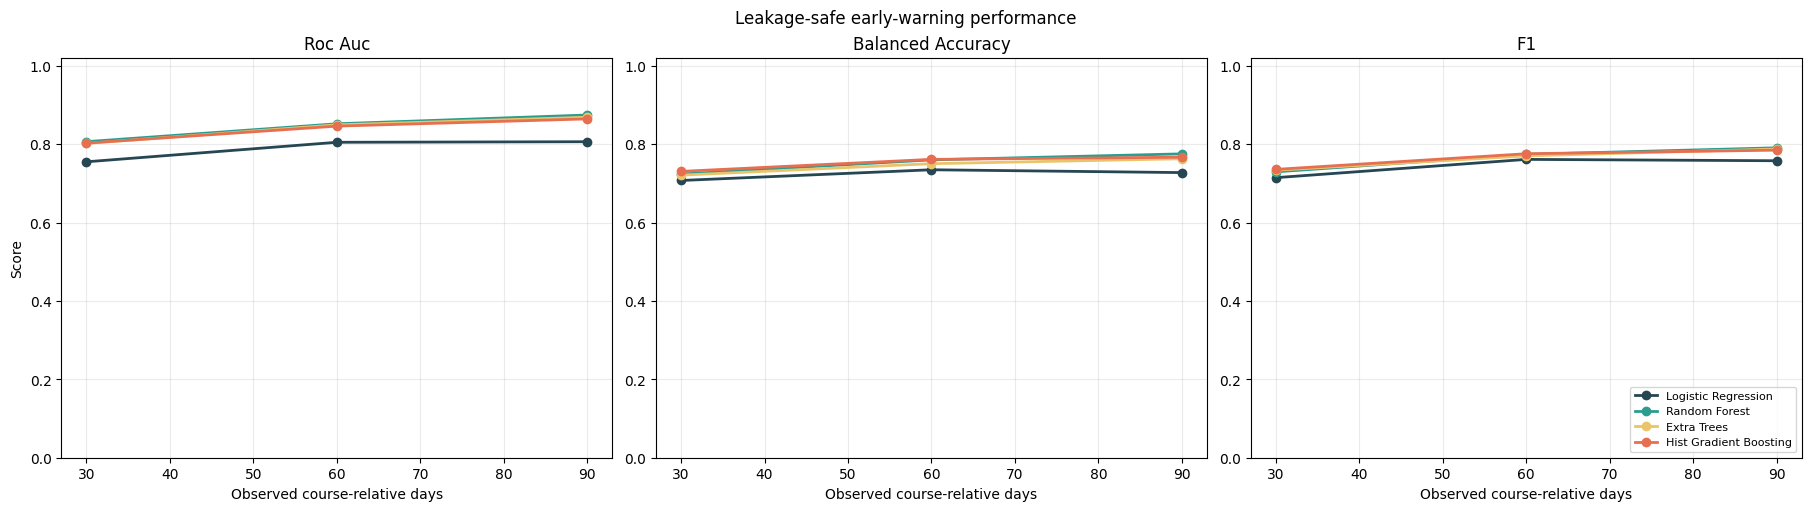

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
colors = {'logistic_regression': '#264653', 'random_forest': '#2a9d8f', 'extra_trees': '#e9c46a', 'hist_gradient_boosting': '#e76f51'}
for axis, metric in zip(axes, ['roc_auc', 'balanced_accuracy', 'f1']):
    for model_name in MODEL_NAMES:
        subset = results[results['model'] == model_name].sort_values('cutoff_days')
        axis.plot(subset['cutoff_days'], subset[metric], marker='o', linewidth=2, label=model_name.replace('_', ' ').title(), color=colors[model_name])
    axis.set_title(metric.replace('_', ' ').title())
    axis.set_xlabel('Observed course-relative days')
    axis.set_ylim(0, 1.02)
    axis.grid(alpha=0.25)
axes[0].set_ylabel('Score')
axes[-1].legend(loc='lower right', fontsize=8)
fig.suptitle('Leakage-safe early-warning performance')
plt.show()

## Confusion matrices at every early-warning cutoff

Confusion matrices make the operational trade-off visible at 30, 60 and 90 observed course-relative days. Rows are actual classes and columns are predicted classes: false negatives are enrollments in the risk class that the planner failed to flag, while false positives are enrollments flagged for support that ultimately were not in the risk class.

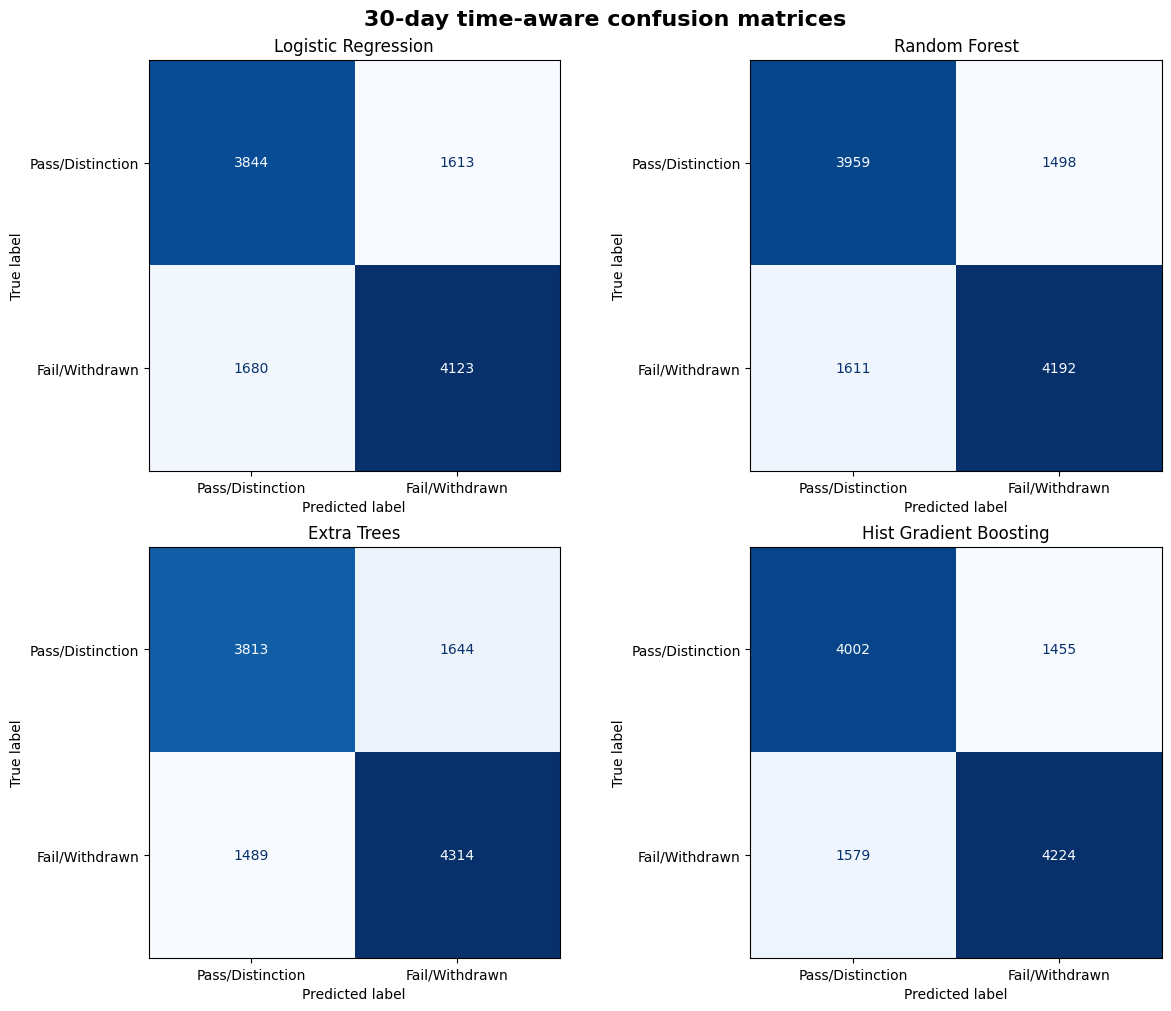

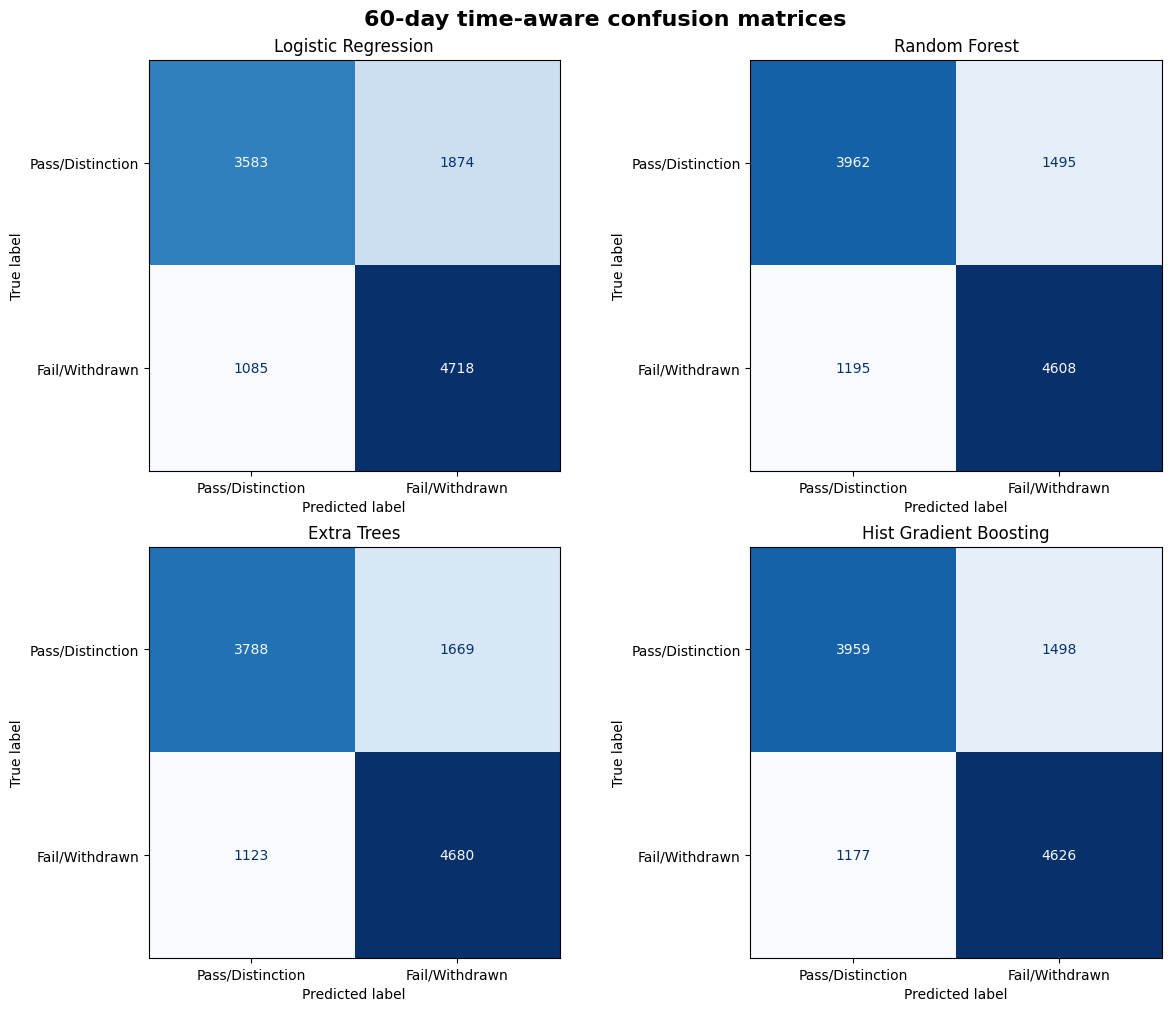

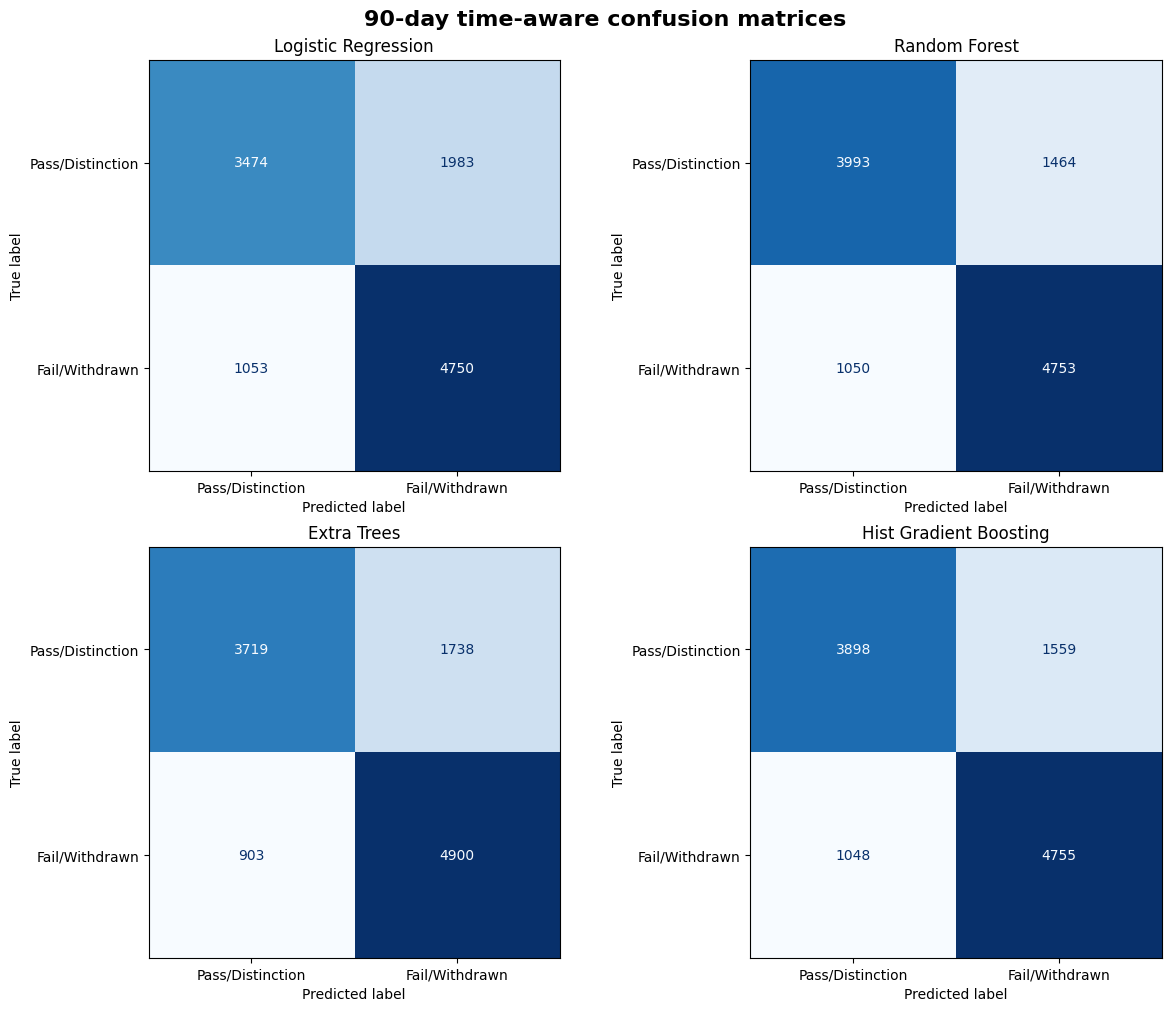

In [6]:
for cutoff in CUTOFFS:
    test_features, test_target = split_by_cutoff[cutoff]
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
    for axis, model_name in zip(axes.ravel(), MODEL_NAMES):
        ConfusionMatrixDisplay.from_estimator(
            fitted_by_cutoff[cutoff][model_name],
            test_features,
            test_target,
            display_labels=['Pass/Distinction', 'Fail/Withdrawn'],
            cmap='Blues',
            colorbar=False,
            ax=axis,
        )
        axis.set_title(model_name.replace('_', ' ').title())
    fig.suptitle(f'{cutoff}-day time-aware confusion matrices', fontsize=16, weight='bold')
    plt.show()

## Interpretation and limitations

The selected model and scores must be taken from the executed result table or the reproducible JSON output generated by `pipeline/early_warning_pipeline.py`; this notebook does not hard-code metrics. The reported statistics describe performance on the held-out latest presentation and should not be treated as uncertainty-free estimates of deployment performance.

The executed comparison selects a model independently at each cutoff using validation PR-AUC, validation ROC-AUC, validation balanced accuracy, and validation F1. The selected algorithm may differ by cutoff. This comparison explains why the selection rule is applied before reading the locked-test metrics rather than by accuracy or F1 alone.

This design still uses the final course outcome as the label, so it measures retrospective discrimination under an early-observation constraint. A production study planner would need prospective validation, intervention-aware evaluation, calibration and threshold selection, and a policy for handling learners with too little observed activity. Holding out the latest presentation reduces temporal leakage from later presentations, but it does not remove all possible distribution shift or establish causal benefit from an intervention.

### Formal rationale for introducing cutoff days

The full-course baseline answers the question: how well can the outcome be classified when the complete course record is available? That question is useful for validating the data and modeling pipeline, but it is not sufficient for a Smart Study Planner. A planner must make decisions while a course is in progress, when the final assessment record, later VLE activity, and future withdrawal information may not yet exist. Using those future records would make the model appear more capable than it could be at deployment.

The cutoff design creates an explicit information boundary. At a cutoff of day `d`, only dated assessment submissions and VLE activity with course-relative dates less than or equal to `d` are aggregated. Future `date_unregistration` is excluded because a later withdrawal date would not be available at the time of prediction. Rebuilding the feature matrix separately for each cutoff prevents later observations from being silently carried into an earlier scenario.

Days 30, 60, and 90 are used as staged evaluation checkpoints. Day 30 represents an early opportunity to identify learners with limited evidence of progress or engagement. Day 60 represents a mid-course point at which additional evidence may improve ranking while support may remain actionable. Day 90 represents a later observation window with more accumulated evidence, allowing the analysis to quantify how much predictive information is gained as intervention lead time decreases. These checkpoints are not presented as universally optimal dates; they are a structured sensitivity analysis of the evidence-versus-lead-time trade-off.

The time-aware presentation split is introduced for the same reason. Training on earlier presentations and testing on the latest presentation better approximates deployment on a future course offering than a random row split. It reduces the possibility that records from the same temporal regime make the evaluation unrealistically easy. The split does not remove all distribution shift, and the final course outcome remains a retrospective label.

The comparison across cutoffs is therefore interpreted as an operational curve, not merely a model leaderboard. If performance improves at later cutoffs, that may indicate that additional evidence is informative, but it also means the planner has less time to intervene. If performance is acceptable at an earlier cutoff, the result may be more valuable operationally even if its aggregate score is lower. A deployment decision must combine these statistics with calibration, support capacity, intervention costs, fairness review, and prospective outcome evaluation.